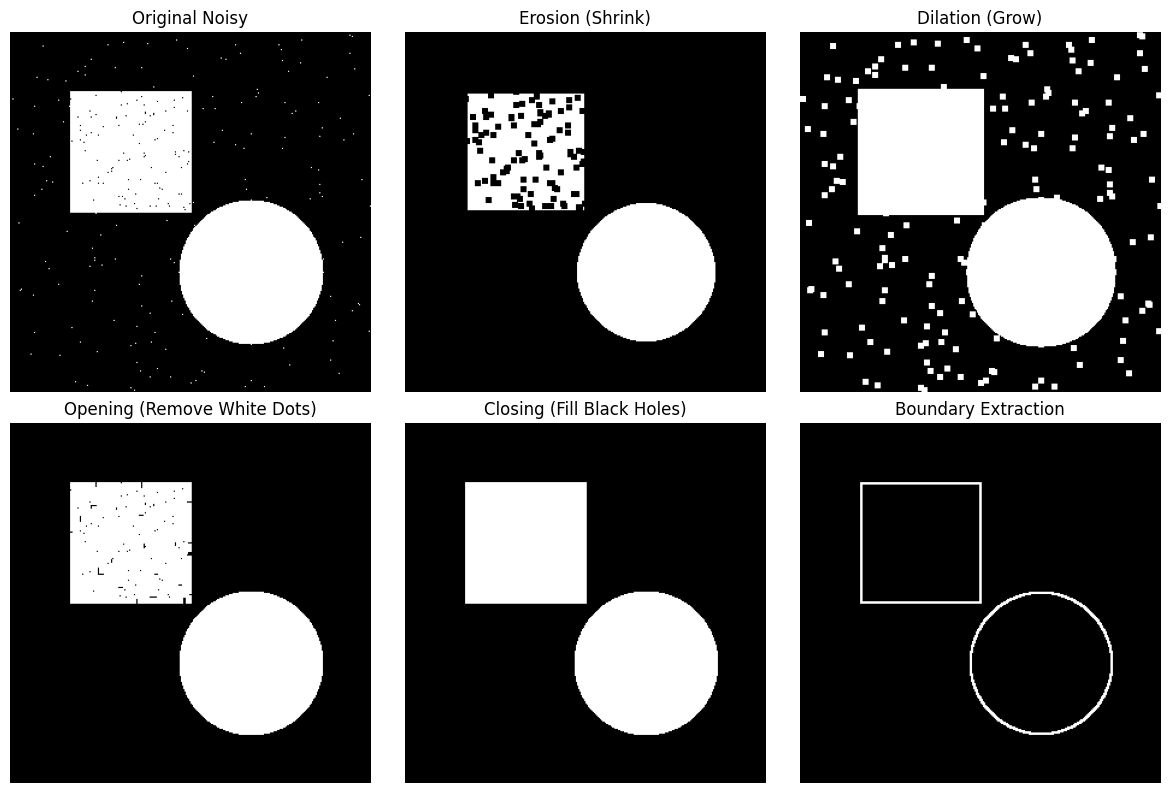

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Step 1: Create a Synthetic Noisy Image ---
# We create a black image (300x300)
img = np.zeros((300, 300), dtype=np.uint8)

# Draw a standard object: A white Rectangle & Circle
cv2.rectangle(img, (50, 50), (150, 150), 255, -1) # White block
cv2.circle(img, (200, 200), 60, 255, -1)          # White circle

# Add "Salt" noise (random white dots in background)
# 'Opening' will fix this
noise_white = np.random.randint(0, 300, (200, 2))
for x, y in noise_white:
    img[y, x] = 255

# Add "Pepper" noise (random black dots inside objects)
# 'Closing' will fix this
noise_black = np.random.randint(50, 150, (100, 2))
for x, y in noise_black:
    img[y, x] = 0

# --- Step 2: Define the Kernel ---
# A 5x5 square block. This is our "Brush".
kernel = np.ones((5, 5), np.uint8)

# --- Step 3: Fundamental Operations ---
erosion = cv2.erode(img, kernel, iterations=1)
dilation = cv2.dilate(img, kernel, iterations=1)

# --- Step 4: Advanced Cleanup (Opening & Closing) ---
# Opening: Removes white noise (Erosion followed by Dilation)
opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)

# Closing: Fills black holes (Dilation followed by Erosion)
# Note: We apply closing on the 'opening' result to get a fully clean image
clean_image = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel)

# --- Step 5: Boundary Extraction ---
# Boundary = Clean Image - Eroded Clean Image
erosion_clean = cv2.erode(clean_image, kernel, iterations=1)
boundary = cv2.subtract(clean_image, erosion_clean)

# --- Display Results ---
titles = ['Original Noisy', 'Erosion (Shrink)', 'Dilation (Grow)', 
          'Opening (Remove White Dots)', 'Closing (Fill Black Holes)', 'Boundary Extraction']
images = [img, erosion, dilation, opening, clean_image, boundary]

plt.figure(figsize=(12, 8))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()